# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Satria Dwi Cahya Fatiawan
- **Email:** satriadwi2005@gmail.com
- **ID Dicoding:** satriadc

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren pertumbuhan jumlah pesanan dan total pendapatan bulanan sepanjang tahun 2017 hingga Agustus 2018, serta 10 kategori produk mana yang menghasilkan pendapatan tertinggi dan terendah?
- **Pertanyaan 2:** Seberapa besar pengaruh keterlambatan pengiriman (selisih antara tanggal pesanan diterima pelanggan dengan estimasi pengiriman) terhadap rata-rata skor ulasan di berbagai negara bagian?

## Import Semua Packages/Library yang Digunakan

In [12]:
# @title
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")
pd.set_option('display.max_columns', None)

## Data Wrangling

### Gathering Data

#### Load df ...

In [13]:
#### Load All Datasets

customers_df = pd.read_csv("customers_dataset.csv")
geolocation_df = pd.read_csv("geolocation_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
order_payments_df = pd.read_csv("order_payments_dataset.csv")
order_reviews_df = pd.read_csv("order_reviews_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
product_category_df = pd.read_csv("product_category_name_translation.csv")
products_df = pd.read_csv("products_dataset.csv")
sellers_df = pd.read_csv("sellers_dataset.csv")

datasets = {
    "customers_df": customers_df,
    "geolocation_df": geolocation_df,
    "order_items_df": order_items_df,
    "order_payments_df": order_payments_df,
    "order_reviews_df": order_reviews_df,
    "orders_df": orders_df,
    "product_category_df": product_category_df,
    "products_df": products_df,
    "sellers_df": sellers_df,
}

for name, df in datasets.items():
    print(f"{name:<22}: {df.shape[0]:>7} baris, {df.shape[1]} kolom")

customers_df          :   99441 baris, 5 kolom
geolocation_df        : 1000163 baris, 5 kolom
order_items_df        :  112650 baris, 7 kolom
order_payments_df     :  103886 baris, 5 kolom
order_reviews_df      :   99224 baris, 7 kolom
orders_df             :   99441 baris, 8 kolom
product_category_df   :      71 baris, 2 kolom
products_df           :   32951 baris, 9 kolom
sellers_df            :    3095 baris, 4 kolom


**Insight:** (Opsional)
- Terdapat 9 tabel relasional pada E-Commerce Public Dataset yang berhasil dimuat, dengan tabel utama transaksi (`orders_df` dan `customers_df`) masing-masing berjumlah 99.441 baris.
- Untuk menjawab 2 pertanyaan bisnis utama (tren pendapatan & performa kategori produk, serta dampak keterlambatan pengiriman terhadap *review score*) dan analisis lanjutan (RFM), tabel inti yang akan digunakan adalah `orders_df`, `order_items_df`, `products_df`, `product_category_df`, `order_reviews_df`, `order_payments_df`, dan `customers_df`.

### Assessing Data

#### Identifying ... problem

In [14]:
#### Identifying Data Quality Issues

for name, df in datasets.items():
    print("=" * 55)
    print(f"TABEL: {name}")
    print(f"Jumlah Duplikat : {df.duplicated().sum()}")

    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if not missing.empty:
        print("Missing Values  :")
        for col, val in missing.items():
            print(f"  - {col}: {val} ({val / len(df) * 100:.2f}%)")
    else:
        print("Missing Values  : Tidak ada")

    print("\nTipe Data Kolom :")
    print(df.dtypes)

# Mengecek ringkasan statistik kolom numerik utama & status pesanan
print("=" * 55)
print("Distribusi Status Pesanan (orders_df):")
print(orders_df["order_status"].value_counts())

print("\nStatistik Harga & Ongkir (order_items_df):")
display(order_items_df[["price", "freight_value"]].describe())

print("\nStatistik Skor Ulasan (order_reviews_df):")
display(order_reviews_df[["review_score"]].describe())

TABEL: customers_df
Jumlah Duplikat : 0
Missing Values  : Tidak ada

Tipe Data Kolom :
customer_id                 object
customer_unique_id          object
customer_zip_code_prefix     int64
customer_city               object
customer_state              object
dtype: object
TABEL: geolocation_df
Jumlah Duplikat : 261831
Missing Values  : Tidak ada

Tipe Data Kolom :
geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                object
geolocation_state               object
dtype: object
TABEL: order_items_df
Jumlah Duplikat : 0
Missing Values  : Tidak ada

Tipe Data Kolom :
order_id                object
order_item_id            int64
product_id              object
seller_id               object
shipping_limit_date     object
price                  float64
freight_value          float64
dtype: object
TABEL: order_payments_df
Jumlah Duplikat : 0
Missing Values  : Tidak ada

Tipe Data Kolom :
order_id 

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000



Statistik Skor Ulasan (order_reviews_df):


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


**Steps to Take:**
- Mengubah tipe data kolom tanggal/waktu yang masih bertipe `object` menjadi `datetime64` pada tabel `orders_df`, `order_items_df`, dan `order_reviews_df`.
- Menangani *missing values* pada `products_df` dengan mengisi kategori produk yang kosong (`610` baris) menjadi `"unknown"` dan menghapus atau mengisi nilai dimensi produk yang hilang (`2` baris) dengan median.
- Menangani *missing values* pada `order_reviews_df` (`review_comment_title` dan `review_comment_message`) dengan mengisi nilai kosong menjadi `"No Comment"` karena pelanggan memang tidak wajib menulis teks ulasan.
- Memfilter `orders_df` berdasarkan `order_status == "delivered"` saat menghitung *revenue* valid dan durasi keterlambatan pengiriman agar *missing values* pada `order_delivered_customer_date` (yang berasal dari pesanan *canceled/shipped/unavailable*) tidak mengganggu kalkulasi.
- Menghapus data duplikat pada `geolocation_df` (`261.831` baris duplikat) jika tabel geografis digunakan.

**Insight:** (Opsional)
- **Kesalahan Tipe Data:** Seluruh kolom *timestamp* pada `orders_df` (5 kolom), `order_items_df` (`shipping_limit_date`), dan `order_reviews_df` (`review_creation_date`, `review_answer_timestamp`) masih terbaca sebagai `object` (string), sehingga perlu dikonversi ke `datetime` sebelum menghitung selisih waktu pengiriman maupun agregasi bulanan.
- **Missing Values:**
  - Pada `orders_df`, terdapat 2.965 baris kosong pada `order_delivered_customer_date` (2,98%), yang wajar terjadi karena ada 2.963 pesanan yang statusnya bukan `delivered` (`shipped`, `canceled`, `unavailable`, dll.).
  - Pada `products_df`, terdapat 610 produk (1,85%) yang tidak memiliki `product_category_name` serta 2 produk tanpa keterangan berat/dimensi fisik.
  - Pada `order_reviews_df`, mayoritas pelanggan tidak mengisi `review_comment_title` (88,34%) dan `review_comment_message` (58,70%), namun kolom `review_score` terisi 100% lengkap (rata-rata skor 4,09 dari 5).
- **Duplikasi Data:** Ditemukan 261.831 baris duplikat pada `geolocation_df`, sedangkan 8 tabel lainnya bersih (0 duplikat).

### Cleaning Data

#### Fixing ... problem

In [15]:
#### Fixing Data Types, Missing Values, and Duplicates

# 1. Mengubah tipe data kolom tanggal/waktu menjadi datetime64
orders_datetime_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in orders_datetime_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df["shipping_limit_date"] = pd.to_datetime(order_items_df["shipping_limit_date"])
order_reviews_df["review_creation_date"] = pd.to_datetime(order_reviews_df["review_creation_date"])
order_reviews_df["review_answer_timestamp"] = pd.to_datetime(order_reviews_df["review_answer_timestamp"])

# 2. Menangani missing values pada products_df
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")
product_num_cols = [
    "product_name_lenght", "product_description_lenght", "product_photos_qty",
    "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"
]
for col in product_num_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# Menambahkan kategori 'unknown' ke tabel translasi agar tidak hilang saat proses merge
if "unknown" not in product_category_df["product_category_name"].values:
    unknown_cat = pd.DataFrame({
        "product_category_name": ["unknown"],
        "product_category_name_english": ["unknown"]
    })
    product_category_df = pd.concat([product_category_df, unknown_cat], ignore_index=True)

# 3. Menangani missing values pada order_reviews_df
order_reviews_df["review_comment_title"] = order_reviews_df["review_comment_title"].fillna("No Title")
order_reviews_df["review_comment_message"] = order_reviews_df["review_comment_message"].fillna("No Comment")

# 4. Menghapus duplikat pada geolocation_df
geolocation_df.drop_duplicates(inplace=True)

# 5. Membuat subset pesanan valid (status 'delivered' dan memiliki tanggal sampai ke pelanggan)
delivered_orders_df = orders_df[orders_df["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]
).copy()

# Verifikasi hasil cleaning
print(f"Tipe data orders_df selesai dikonversi        : {orders_df['order_purchase_timestamp'].dtype}")
print(f"Sisa missing values di products_df           : {products_df.isnull().sum().sum()}")
print(f"Sisa missing values di order_reviews_df      : {order_reviews_df.isnull().sum().sum()}")
print(f"Jumlah baris geolocation_df setelah dedup    : {len(geolocation_df)}")
print(f"Jumlah pesanan valid (delivered_orders_df)   : {len(delivered_orders_df)} baris")

Tipe data orders_df selesai dikonversi        : datetime64[ns]
Sisa missing values di products_df           : 0
Sisa missing values di order_reviews_df      : 0
Jumlah baris geolocation_df setelah dedup    : 738332
Jumlah pesanan valid (delivered_orders_df)   : 96470 baris


**Insight:** (Opsional)
- Seluruh kolom *timestamp* pada `orders_df`, `order_items_df`, dan `order_reviews_df` telah berhasil dikonversi menjadi `datetime64[ns]`, sehingga siap digunakan untuk kalkulasi durasi keterlambatan dan tren bulanan.
- *Missing values* pada `products_df` dan `order_reviews_df` kini bersih (0 *null*), serta ditambahkan entri `"unknown"` pada tabel translasi kategori agar seluruh produk tetap terhitung saat penggabungan tabel.
- Data duplikat pada `geolocation_df` telah dihapus sehingga menyisakan 738.332 baris unik.
- Terbentuk subset `delivered_orders_df` sebanyak **96.470 pesanan valid** (status `delivered` dengan tanggal pengiriman lengkap) yang menjadi basis akurat untuk menganalisis *revenue* dan ketepatan waktu pengiriman.

## Exploratory Data Analysis (EDA)

### Explore ...

In [16]:
### Explore Revenue Trends, Product Categories, and Delivery Impact on Reviews

# 1. Membuat fitur metrik keterlambatan pengiriman pada delivered_orders_df
delivered_orders_df["delivery_delay_days"] = (
    delivered_orders_df["order_delivered_customer_date"] - delivered_orders_df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400.0

delivered_orders_df["delivery_status"] = np.where(
    delivered_orders_df["delivery_delay_days"] > 0, "Late", "On Time"
)

# 2. Menggabungkan tabel produk dengan terjemahan kategori bahasa Inggris
products_full_df = pd.merge(
    products_df, product_category_df, on="product_category_name", how="left"
)
products_full_df["product_category_name_english"] = products_full_df["product_category_name_english"].fillna(
    products_full_df["product_category_name"]
)

# 3. Menggabungkan pesanan valid dengan data pelanggan, item pesanan, dan produk
orders_cust_df = pd.merge(delivered_orders_df, customers_df, on="customer_id", how="left")
items_prod_df = pd.merge(order_items_df, products_full_df, on="product_id", how="left")
all_df = pd.merge(orders_cust_df, items_prod_df, on="order_id", how="inner")

# Filter periode analisis sesuai pertanyaan bisnis: Januari 2017 - Agustus 2018
df_period = all_df[
    (all_df["order_purchase_timestamp"] >= "2017-01-01") &
    (all_df["order_purchase_timestamp"] < "2018-09-01")
].copy()
df_period["year_month"] = df_period["order_purchase_timestamp"].dt.to_period("M")

# --- Eksplorasi 1: Tren Pesanan & Pendapatan Bulanan ---
monthly_trend_df = df_period.groupby("year_month").agg(
    order_count=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

print("=== TREN PESANAN & PENDAPATAN BULANAN (JAN 2017 - AGU 2018) ===")
display(monthly_trend_df)

# --- Eksplorasi 2: Performa Kategori Produk (Top 10 & Bottom 10) ---
category_perf_df = df_period.groupby("product_category_name_english").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_item_id", "count")
).sort_values(by="total_revenue", ascending=False).reset_index()

print("\n=== TOP 10 KATEGORI PRODUK BERDASARKAN REVENUE ===")
display(category_perf_df.head(10))

print("\n=== BOTTOM 10 KATEGORI PRODUK BERDASARKAN REVENUE ===")
display(category_perf_df.tail(10))

# --- Eksplorasi 3: Dampak Keterlambatan Pengiriman terhadap Review Score ---
reviews_dedup_df = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()
orders_review_df = pd.merge(orders_cust_df, reviews_dedup_df, on="order_id", how="inner")
orders_review_period = orders_review_df[
    (orders_review_df["order_purchase_timestamp"] >= "2017-01-01") &
    (orders_review_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

delivery_review_summary = orders_review_period.groupby("delivery_status").agg(
    order_count=("order_id", "count"),
    avg_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median")
).reset_index()
delivery_review_summary["percentage (%)"] = (
    delivery_review_summary["order_count"] / delivery_review_summary["order_count"].sum() * 100
).round(2)

print("\n=== PERBANDINGAN REVIEW SCORE: ON TIME VS LATE ===")
display(delivery_review_summary)

state_delivery_summary = orders_review_period.groupby("customer_state").agg(
    total_orders=("order_id", "count"),
    late_orders=("delivery_status", lambda x: (x == "Late").sum()),
    avg_review_score=("review_score", "mean")
).reset_index()
state_delivery_summary["late_rate (%)"] = (
    state_delivery_summary["late_orders"] / state_delivery_summary["total_orders"] * 100
).round(2)

print("\n=== TOP 10 NEGARA BAGIAN DENGAN TINGKAT KETERLAMBATAN TERTINGGI (MIN. 100 PESANAN) ===")
display(
    state_delivery_summary[state_delivery_summary["total_orders"] >= 100]
    .sort_values(by="late_rate (%)", ascending=False)
    .head(10)
)

=== TREN PESANAN & PENDAPATAN BULANAN (JAN 2017 - AGU 2018) ===


,year_month,order_count,total_revenue
0,2017-01,750,111798.36
1,2017-02,1653,234223.40
2,2017-03,2546,359198.85
3,2017-04,2303,340669.68
4,2017-05,3545,489159.25
5,2017-06,3135,421923.37
6,2017-07,3872,481604.52
7,2017-08,4193,554699.70
8,2017-09,4150,607399.67
9,2017-10,4478,648247.65



=== TOP 10 KATEGORI PRODUK BERDASARKAN REVENUE ===


,product_category_name_english,total_revenue,total_orders,total_items
0,health_beauty,1229557.50,8610,9422
1,watches_gifts,1163187.91,5489,5853
2,bed_bath_table,1022955.77,9267,10945
3,sports_leisure,952661.40,7512,8413
4,computers_accessories,887944.60,6517,7631
5,furniture_decor,706237.17,6258,8095
6,housewares,614341.62,5734,6783
7,cool_stuff,609158.00,3552,3711
8,auto,577721.09,3801,4131
9,garden_tools,469135.40,3443,4263



=== BOTTOM 10 KATEGORI PRODUK BERDASARKAN REVENUE ===


,product_category_name_english,total_revenue,total_orders,total_items
64,fashion_sport,2094.52,26,29
65,la_cuisine,2054.99,13,14
66,arts_and_craftmanship,1814.01,23,24
67,diapers_and_hygiene,1365.89,24,36
68,pc_gamer,1306.95,7,8
69,flowers,1110.04,29,33
70,home_comfort_2,760.27,24,30
71,cds_dvds_musicals,730.00,12,14
72,fashion_childrens_clothes,519.95,7,7
73,security_and_services,283.29,2,2



=== PERBANDINGAN REVIEW SCORE: ON TIME VS LATE ===


,delivery_status,order_count,avg_review_score,median_review_score,percentage (%)
0,Late,7658,2.566728,2.0,8.01
1,On Time,87902,4.295086,5.0,91.99



=== TOP 10 NEGARA BAGIAN DENGAN TINGKAT KETERLAMBATAN TERTINGGI (MIN. 100 PESANAN) ===


,customer_state,total_orders,late_orders,avg_review_score,late_rate (%)
1,AL,393,92,3.852417,23.41
9,MA,709,137,3.830042,19.32
16,PI,470,75,3.993617,15.96
5,CE,1267,194,3.937648,15.31
24,SE,331,50,3.900302,15.11
4,BA,3226,443,3.929634,13.73
18,RJ,12172,1623,3.965193,13.33
26,TO,273,35,4.153846,12.82
13,PA,929,111,3.908504,11.95
7,ES,1966,234,4.079858,11.90


**Insight:** (Opsional)
- **Tren Pertumbuhan Bulanan:** Jumlah pesanan dan *revenue* tumbuh konsisten sepanjang 2017 dan mencapai puncaknya pada **November 2017** (7.288 pesanan dengan *revenue* **BRL 987.648,07**, bertepatan dengan momentum *Black Friday*), sementara titik terendah berada di awal periode pada **Januari 2017** (750 pesanan dengan *revenue* **BRL 111.798,36**). Memasuki Januari–Agustus 2018, volume transaksi stabil di kisaran 6.096–7.069 pesanan per bulan.
- **Performa Kategori Produk:** Tiga kategori penyumbang *revenue* terbesar adalah **`health_beauty`** (BRL 1.229.557,50), **`watches_gifts`** (BRL 1.163.187,91), dan **`bed_bath_table`** (BRL 1.022.955,77). Sebaliknya, kategori dengan pendapatan terendah adalah **`security_and_services`** (BRL 283,29) dan **`fashion_childrens_clothes`** (BRL 519,95).
- **Dampak Keterlambatan terhadap Kepuasan Pelanggan:** Dari 95.560 pesanan berulasan pada periode tersebut, **91,99%** tiba tepat waktu (*On Time*) dengan rata-rata skor ulasan **4,30** (median 5,0). Namun pada **8,01%** pesanan yang terlambat (*Late*), rata-rata skor ulasan anjlok tajam sebesar **1,73 poin** menjadi **2,57** (median 2,0).
- **Sebaran Wilayah Keterlambatan:** Negara bagian dengan tingkat keterlambatan tertinggi (minimal 100 pesanan) didominasi wilayah timur laut Brasil seperti **AL (23,41%)**, **MA (19,32%)**, dan **PI (15,96%)**, sedangkan di antara negara bagian dengan volume pesanan terbesar, **RJ (Rio de Janeiro)** mencatat tingkat keterlambatan tertinggi sebesar **13,33%** (rata-rata skor ulasan turun ke 3,97).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

In [17]:
'''
Pertanyaan 1: Bagaimana tren pertumbuhan jumlah pesanan dan total pendapatan (revenue) bulanan pada periode
Januari 2017 hingga Agustus 2018, serta 10 kategori produk apa saja yang menghasilkan pendapatan tertinggi dan
terendah?
'''


'\nPertanyaan 1: Bagaimana tren pertumbuhan jumlah pesanan dan total pendapatan (revenue) bulanan pada periode \nJanuari 2017 hingga Agustus 2018, serta 10 kategori produk apa saja yang menghasilkan pendapatan tertinggi dan \nterendah?\n'

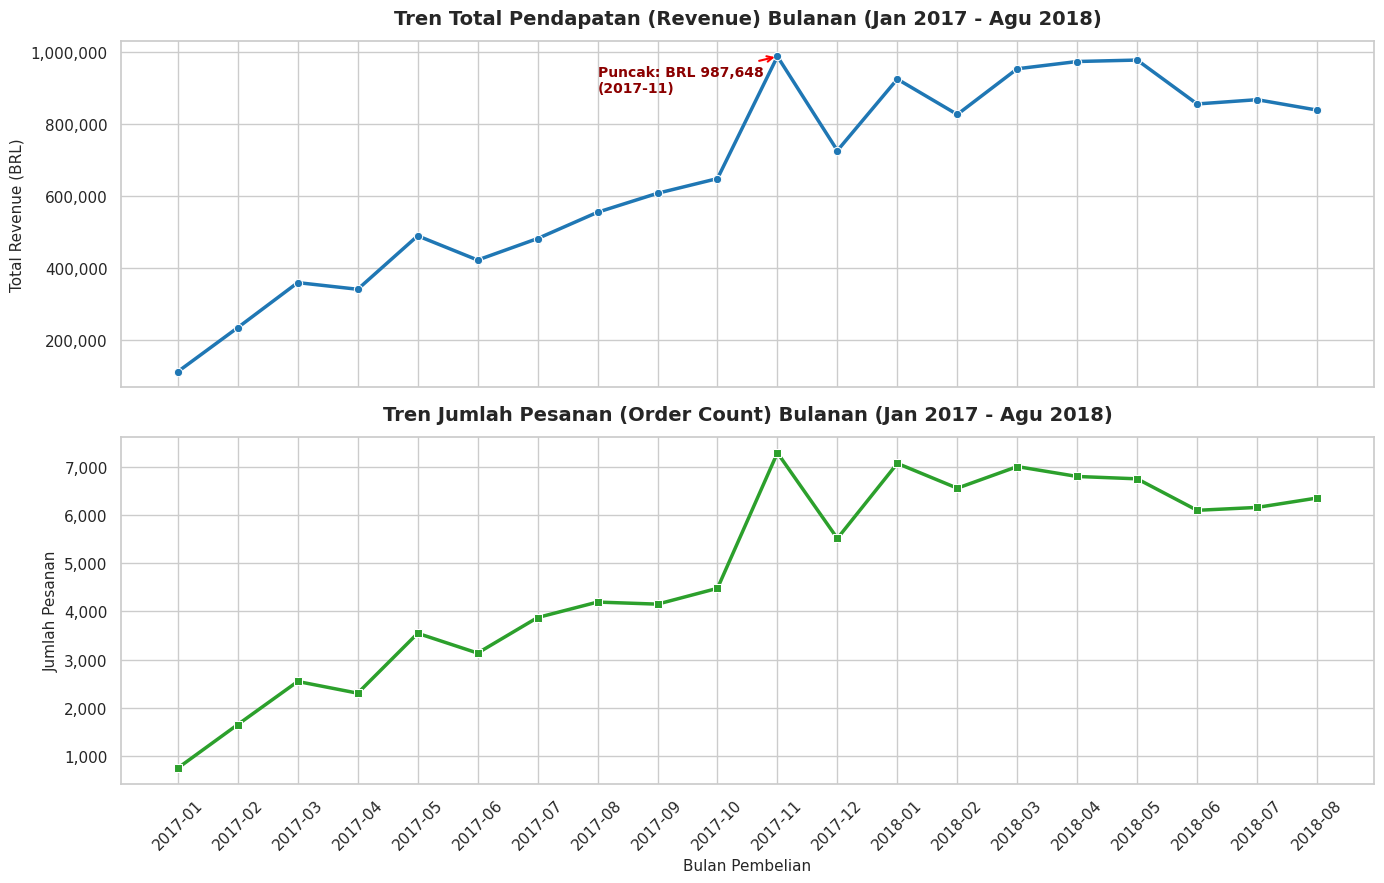

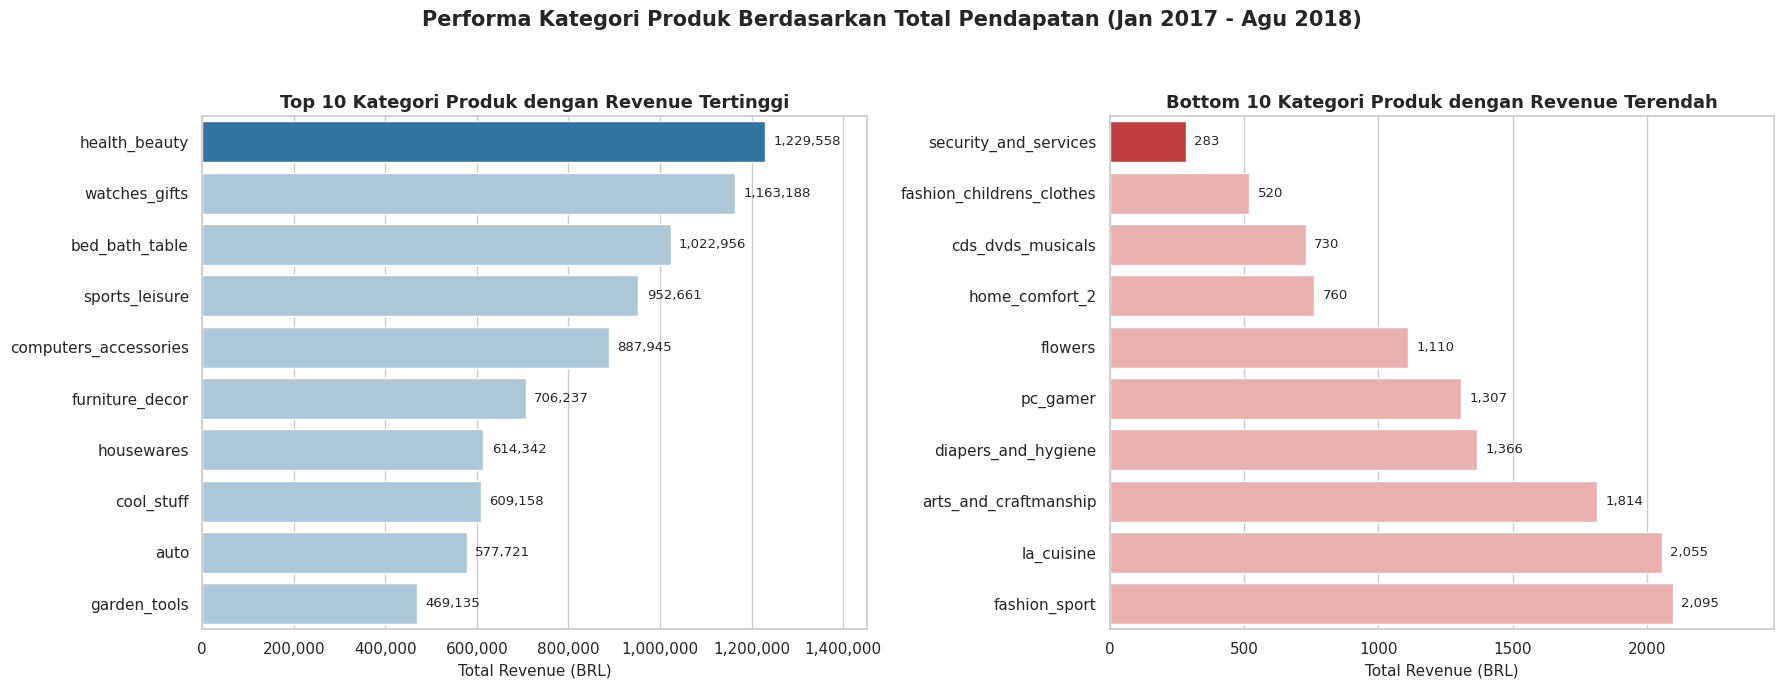

In [18]:
# --- Visualisasi 1A: Tren Pendapatan & Jumlah Pesanan Bulanan ---
monthly_plot = monthly_trend_df.copy()
monthly_plot["year_month_str"] = monthly_plot["year_month"].astype(str)

fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(14, 9), sharex=True)

# Grafik Atas: Total Revenue Bulanan
sns.lineplot(
    data=monthly_plot, x="year_month_str", y="total_revenue",
    marker="o", linewidth=2.5, color="#1f77b4", ax=ax[0]
)
ax[0].set_title("Tren Total Pendapatan (Revenue) Bulanan (Jan 2017 - Agu 2018)", fontsize=14, fontweight="bold", pad=12)
ax[0].set_ylabel("Total Revenue (BRL)", fontsize=11)
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

peak_idx = monthly_plot["total_revenue"].idxmax()
ax[0].annotate(
    f"Puncak: BRL {monthly_plot.loc[peak_idx, 'total_revenue']:,.0f}\n({monthly_plot.loc[peak_idx, 'year_month_str']})",
    xy=(peak_idx, monthly_plot.loc[peak_idx, "total_revenue"]),
    xytext=(peak_idx - 3, monthly_plot.loc[peak_idx, "total_revenue"] * 0.90),
    arrowprops=dict(arrowstyle="->", color="red", lw=1.5),
    fontsize=10, fontweight="bold", color="darkred"
)

# Grafik Bawah: Jumlah Pesanan Bulanan
sns.lineplot(
    data=monthly_plot, x="year_month_str", y="order_count",
    marker="s", linewidth=2.5, color="#2ca02c", ax=ax[1]
)
ax[1].set_title("Tren Jumlah Pesanan (Order Count) Bulanan (Jan 2017 - Agu 2018)", fontsize=14, fontweight="bold", pad=12)
ax[1].set_ylabel("Jumlah Pesanan", fontsize=11)
ax[1].set_xlabel("Bulan Pembelian", fontsize=11)
ax[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# --- Visualisasi 1B: Top 10 & Bottom 10 Kategori Produk berdasarkan Revenue ---
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

top_10_cat = category_perf_df.head(10)
bottom_10_cat = category_perf_df.tail(10).sort_values(by="total_revenue", ascending=True)

# Top 10 Kategori
colors_top = ["#1f77b4" if i == 0 else "#a6c8e0" for i in range(len(top_10_cat))]
sns.barplot(
    data=top_10_cat, x="total_revenue", y="product_category_name_english",
    hue="product_category_name_english", palette=colors_top, dodge=False, ax=ax[0]
)
if ax[0].get_legend():
    ax[0].get_legend().remove()
ax[0].set_title("Top 10 Kategori Produk dengan Revenue Tertinggi", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=11)
ax[0].set_ylabel(None)
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
for bar in ax[0].patches:
    w = bar.get_width()
    if w > 0:
        ax[0].text(w + top_10_cat["total_revenue"].max() * 0.015, bar.get_y() + bar.get_height() / 2,
                   f"{w:,.0f}", va="center", ha="left", fontsize=9.5)
ax[0].set_xlim(0, top_10_cat["total_revenue"].max() * 1.18)

# Bottom 10 Kategori
colors_bot = ["#d62728" if i == 0 else "#f2a6a6" for i in range(len(bottom_10_cat))]
sns.barplot(
    data=bottom_10_cat, x="total_revenue", y="product_category_name_english",
    hue="product_category_name_english", palette=colors_bot, dodge=False, ax=ax[1]
)
if ax[1].get_legend():
    ax[1].get_legend().remove()
ax[1].set_title("Bottom 10 Kategori Produk dengan Revenue Terendah", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=11)
ax[1].set_ylabel(None)
for bar in ax[1].patches:
    w = bar.get_width()
    if w > 0:
        ax[1].text(w + bottom_10_cat["total_revenue"].max() * 0.015, bar.get_y() + bar.get_height() / 2,
                   f"{w:,.0f}", va="center", ha="left", fontsize=9.5)
ax[1].set_xlim(0, bottom_10_cat["total_revenue"].max() * 1.18)

plt.suptitle("Performa Kategori Produk Berdasarkan Total Pendapatan (Jan 2017 - Agu 2018)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

### Pertanyaan 2:

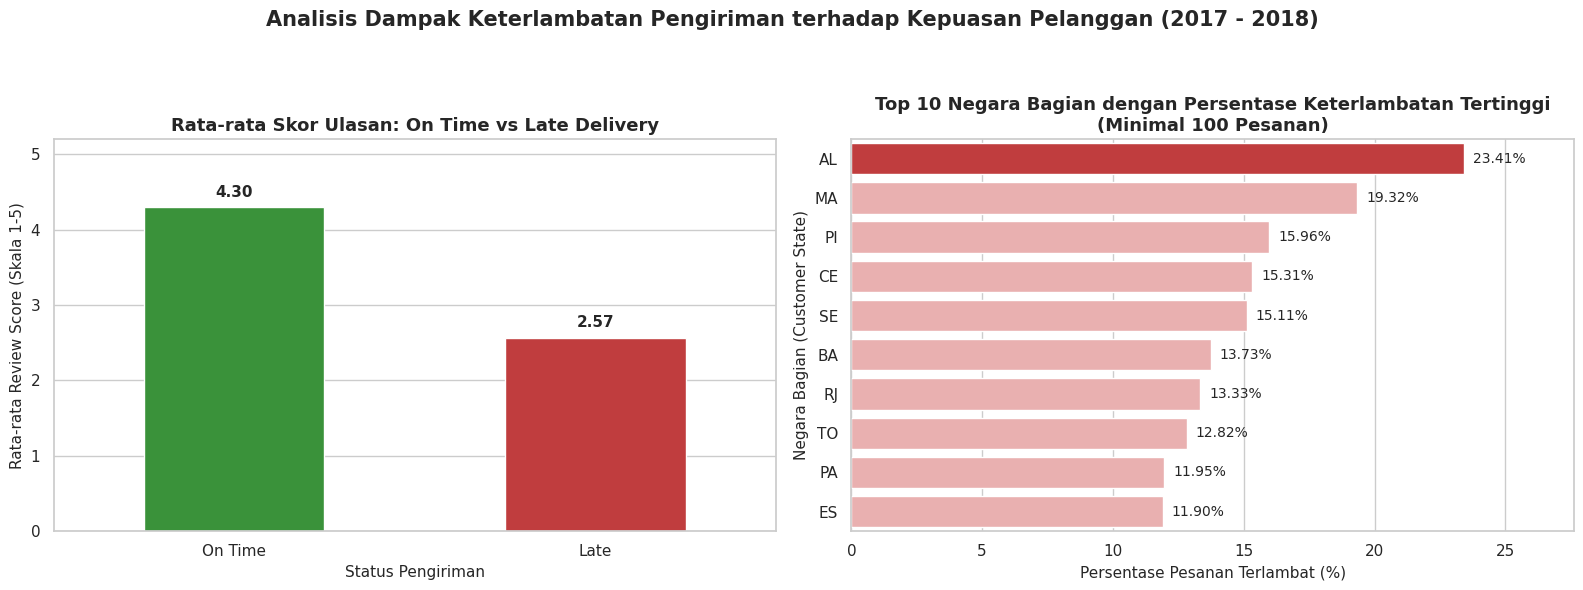

In [19]:
'''
Pertanyaan 2: Seberapa besar dampak keterlambatan pengiriman terhadap penurunan rata-rata skor ulasan pelanggan
(review score) di seluruh negara bagian selama periode 2017–2018?
'''

top_late_states = (
    state_delivery_summary[state_delivery_summary["total_orders"] >= 100]
    .sort_values(by="late_rate (%)", ascending=False)
    .head(10)
)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Grafik Kiri: Rata-rata Review Score On Time vs Late
order_status_list = ["On Time", "Late"]
delivery_plot = delivery_review_summary.set_index("delivery_status").loc[order_status_list].reset_index()
sns.barplot(
    data=delivery_plot, x="delivery_status", y="avg_review_score",
    hue="delivery_status", palette=["#2ca02c", "#d62728"], dodge=False, ax=ax[0], width=0.5
)
if ax[0].get_legend():
    ax[0].get_legend().remove()
ax[0].set_title("Rata-rata Skor Ulasan: On Time vs Late Delivery", fontsize=13, fontweight="bold")
ax[0].set_xlabel("Status Pengiriman", fontsize=11)
ax[0].set_ylabel("Rata-rata Review Score (Skala 1-5)", fontsize=11)
ax[0].set_ylim(0, 5.2)
for bar in ax[0].patches:
    h = bar.get_height()
    if h > 0:
        ax[0].text(bar.get_x() + bar.get_width() / 2, h + 0.1,
                   f"{h:.2f}", ha="center", va="bottom", fontsize=11, fontweight="bold")

# Grafik Kanan: Top 10 Negara Bagian dengan Tingkat Keterlambatan Tertinggi
state_colors = ["#d62728" if i == 0 else "#f2a6a6" for i in range(len(top_late_states))]
sns.barplot(
    data=top_late_states, x="late_rate (%)", y="customer_state",
    hue="customer_state", palette=state_colors, dodge=False, ax=ax[1]
)
if ax[1].get_legend():
    ax[1].get_legend().remove()
ax[1].set_title("Top 10 Negara Bagian dengan Persentase Keterlambatan Tertinggi\n(Minimal 100 Pesanan)", fontsize=13, fontweight="bold")
ax[1].set_xlabel("Persentase Pesanan Terlambat (%)", fontsize=11)
ax[1].set_ylabel("Negara Bagian (Customer State)", fontsize=11)
ax[1].set_xlim(0, top_late_states["late_rate (%)"].max() * 1.18)
for bar in ax[1].patches:
    w = bar.get_width()
    if w > 0:
        ax[1].text(w + top_late_states["late_rate (%)"].max() * 0.015, bar.get_y() + bar.get_height() / 2,
                   f"{w:.2f}%", va="center", ha="left", fontsize=10)

plt.suptitle("Analisis Dampak Keterlambatan Pengiriman terhadap Kepuasan Pelanggan (2017 - 2018)", fontsize=15, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Insight:** (Opsional)
- Terdapat 9 tabel relasional pada E-Commerce Public Dataset yang berhasil dimuat, dengan tabel utama transaksi (`orders_df` dan `customers_df`) masing-masing berjumlah 99.441 baris.
- Untuk menjawab 2 pertanyaan bisnis utama (tren pendapatan & performa kategori produk, serta dampak keterlambatan pengiriman terhadap *review score*) dan analisis lanjutan (RFM), tabel inti yang akan digunakan adalah `orders_df`, `order_items_df`, `products_df`, `product_category_df`, `order_reviews_df`, `order_payments_df`, dan `customers_df`.

## Analisis Lanjutan (Opsional)

=== RINGKASAN STATISTIK METRIK RFM ===


,recency,frequency,monetary
count,93096.00,93096.00,93096.00
mean,236.71,1.03,141.57
std,150.94,0.21,215.77
min,1.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.16
max,602.00,15.00,13440.00



=== DISTRIBUSI SEGMEN PELANGGAN RFM ===


,segment,customer_count,avg_recency,avg_frequency,avg_monetary,total_revenue,pct_customers (%),pct_revenue (%)
0,Need Attention,23340,276.246658,1.031020,139.863881,3264422.99,25.07,24.77
1,At Risk / Hibernating,23198,448.214199,1.027158,141.726235,3287765.21,24.92,24.95
2,Recent Customers,23014,111.176284,1.010428,47.162680,1085401.92,24.72,8.24
3,Potential Loyalists (High Value),22244,111.796125,1.000000,231.571248,5151070.84,23.89,39.08
4,Champions / Loyal,1300,112.450769,2.163846,300.859223,391116.99,1.40,2.97


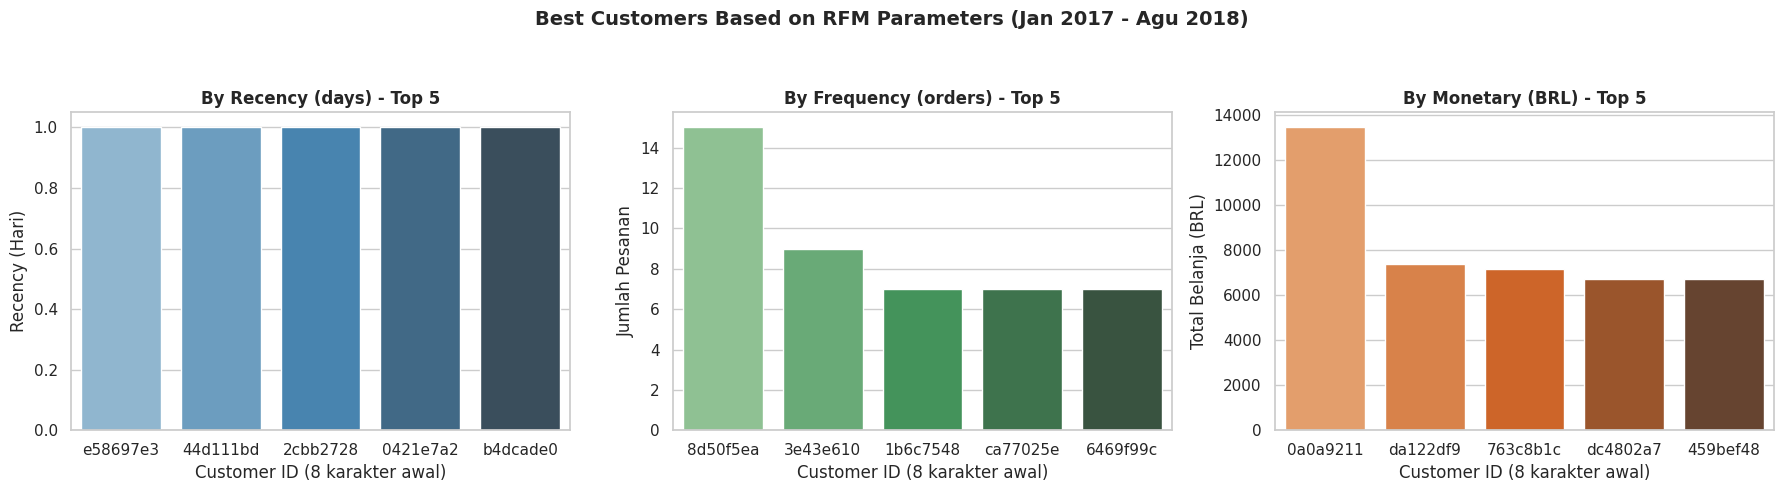

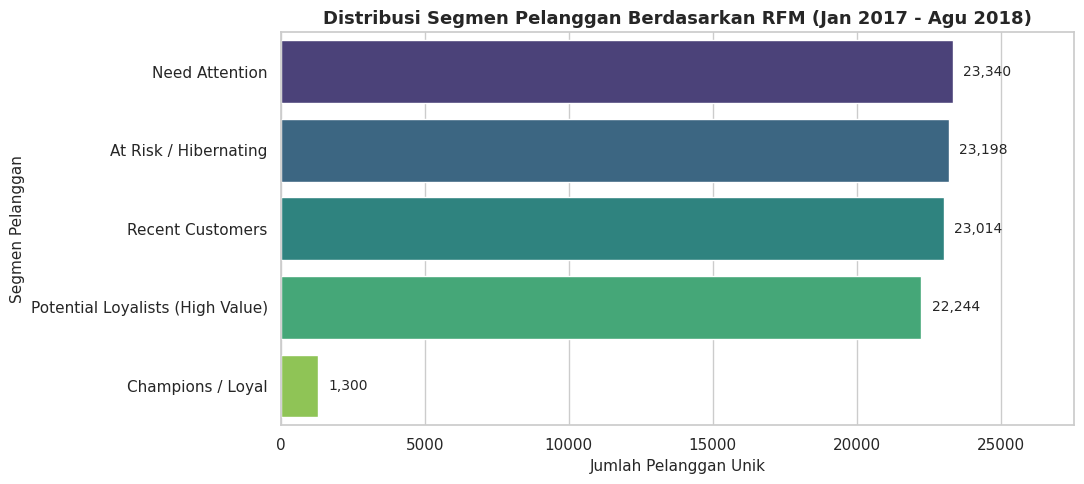

In [20]:
### Analisis Lanjutan: RFM Analysis (Recency, Frequency, Monetary)

# Menggunakan customer_unique_id untuk mengidentifikasi perilaku belanja pelanggan unik
recent_date = df_period["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm_df = df_period.groupby("customer_unique_id", as_index=False).agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("price", "sum")
)

rfm_df["recency"] = (recent_date - rfm_df["max_order_timestamp"]).dt.days
rfm_df.drop(columns=["max_order_timestamp"], inplace=True)

print("=== RINGKASAN STATISTIK METRIK RFM ===")
display(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

# Pemberian skor RFM (1-4) & segmentasi pelanggan
rfm_df["r_score"] = pd.qcut(rfm_df["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)
rfm_df["f_score"] = np.where(rfm_df["frequency"] == 1, 1, np.where(rfm_df["frequency"] == 2, 3, 4))

def assign_segment(row):
    if row["frequency"] >= 2 and row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Champions / Loyal"
    elif row["r_score"] >= 3 and row["m_score"] >= 3:
        return "Potential Loyalists (High Value)"
    elif row["r_score"] >= 3:
        return "Recent Customers"
    elif row["r_score"] == 2:
        return "Need Attention"
    else:
        return "At Risk / Hibernating"

rfm_df["segment"] = rfm_df.apply(assign_segment, axis=1)

segment_summary = rfm_df.groupby("segment").agg(
    customer_count=("customer_unique_id", "count"),
    avg_recency=("recency", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_monetary=("monetary", "mean"),
    total_revenue=("monetary", "sum")
).sort_values(by="customer_count", ascending=False).reset_index()

segment_summary["pct_customers (%)"] = (
    segment_summary["customer_count"] / segment_summary["customer_count"].sum() * 100
).round(2)
segment_summary["pct_revenue (%)"] = (
    segment_summary["total_revenue"] / segment_summary["total_revenue"].sum() * 100
).round(2)

print("\n=== DISTRIBUSI SEGMEN PELANGGAN RFM ===")
display(segment_summary)

# Visualisasi 1: Top 5 Best Customers berdasarkan R, F, M
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5).copy()
top_recency["short_id"] = top_recency["customer_unique_id"].str[:8]
sns.barplot(data=top_recency, x="short_id", y="recency", hue="short_id", palette="Blues_d", dodge=False, ax=ax[0])
if ax[0].get_legend(): ax[0].get_legend().remove()
ax[0].set_title("By Recency (days) - Top 5", fontsize=12, fontweight="bold")
ax[0].set_xlabel("Customer ID (8 karakter awal)")
ax[0].set_ylabel("Recency (Hari)")

top_freq = rfm_df.sort_values(by=["frequency", "monetary"], ascending=[False, False]).head(5).copy()
top_freq["short_id"] = top_freq["customer_unique_id"].str[:8]
sns.barplot(data=top_freq, x="short_id", y="frequency", hue="short_id", palette="Greens_d", dodge=False, ax=ax[1])
if ax[1].get_legend(): ax[1].get_legend().remove()
ax[1].set_title("By Frequency (orders) - Top 5", fontsize=12, fontweight="bold")
ax[1].set_xlabel("Customer ID (8 karakter awal)")
ax[1].set_ylabel("Jumlah Pesanan")

top_mon = rfm_df.sort_values(by="monetary", ascending=False).head(5).copy()
top_mon["short_id"] = top_mon["customer_unique_id"].str[:8]
sns.barplot(data=top_mon, x="short_id", y="monetary", hue="short_id", palette="Oranges_d", dodge=False, ax=ax[2])
if ax[2].get_legend(): ax[2].get_legend().remove()
ax[2].set_title("By Monetary (BRL) - Top 5", fontsize=12, fontweight="bold")
ax[2].set_xlabel("Customer ID (8 karakter awal)")
ax[2].set_ylabel("Total Belanja (BRL)")

plt.suptitle("Best Customers Based on RFM Parameters (Jan 2017 - Agu 2018)", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

# Visualisasi 2: Distribusi Jumlah Pelanggan per Segmen
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=segment_summary, x="customer_count", y="segment", hue="segment", palette="viridis", dodge=False, ax=ax)
if ax.get_legend(): ax.get_legend().remove()
ax.set_title("Distribusi Segmen Pelanggan Berdasarkan RFM (Jan 2017 - Agu 2018)", fontsize=13, fontweight="bold")
ax.set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
ax.set_ylabel("Segmen Pelanggan", fontsize=11)
ax.set_xlim(0, segment_summary["customer_count"].max() * 1.18)
for bar in ax.patches:
    w = bar.get_width()
    if w > 0:
        ax.text(w + segment_summary["customer_count"].max() * 0.015, bar.get_y() + bar.get_height() / 2,
                f"{int(w):,}", va="center", ha="left", fontsize=10)
plt.tight_layout()
plt.show()

**Insight:**
- **Karakteristik Transaksi Pelanggan (93.096 Pelanggan Unik):**
  - **Recency:** Rata-rata pelanggan terakhir bertransaksi **236,71 hari** yang lalu (median **218 hari**).
  - **Frequency:** Mayoritas sangat besar (**97,00%** atau 90.307 pelanggan) hanya melakukan **1 kali transaksi** (*one-time buyer*), sedangkan hanya **3,00%** (2.789 pelanggan) yang melakukan pembelian berulang (*repeat order*, maksimal hingga 15 kali).
  - **Monetary:** Rata-rata pengeluaran per pelanggan unik adalah **BRL 141,57** (median **BRL 89,70**), dengan nilai belanja tertinggi mencapai **BRL 13.440,00**.
- **Segmentasi Pelanggan & Peluang Retensi:**
  - Segmen **Potential Loyalists (High Value)** mencakup **23,89%** pelanggan (22.244 orang) namun menyumbang porsi pendapatan terbesar yaitu **39,08%** (BRL 5,15 juta). Pelanggan di segmen ini baru saja berbelanja dengan nilai transaksi tinggi, sehingga menjadi target utama kampanye *repeat order* (misalnya lewat kupon pembelian kedua).
  - Sebaliknya, hampir separuh basis pelanggan berada di segmen **Need Attention** (**25,07%**) dan **At Risk / Hibernating** (**24,92%**) yang membutuhkan kampanye reaktivasi (*win-back campaign*).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang periode Januari 2017 hingga Agustus 2018, volume pesanan dan total pendapatan (*revenue*) menunjukkan tren pertumbuhan signifikan sepanjang tahun 2017—dari titik terendah pada **Januari 2017** (750 pesanan; **BRL 111.798,36**) hingga mencapai puncaknya pada **November 2017** (7.288 pesanan; **BRL 987.648,07**)—kemudian bertahan stabil di kisaran **BRL 826.000–977.000** per bulan pada Januari–Agustus 2018. Dari sisi kategori produk, **`health_beauty`** (BRL 1.229.557,50), **`watches_gifts`** (BRL 1.163.187,91), dan **`bed_bath_table`** (BRL 1.022.955,77) menjadi kontributor pendapatan utama, sedangkan **`security_and_services`** (BRL 283,29) dan **`fashion_childrens_clothes`** (BRL 519,95) mencatat kontribusi terendah.
- **Conclusion pertanyaan 2:** Ketepatan waktu pengiriman terbukti berdampak sangat signifikan terhadap tingkat kepuasan pelanggan. Pesanan yang tiba tepat waktu (*On Time*, **91,99%** dari total pesanan berulasan) memperoleh rata-rata skor ulasan **4,30** (median 5,0), sedangkan pesanan yang mengalami keterlambatan (*Late*, **8,01%**) mengalami penurunan skor ulasan tajam sebesar **1,73 poin** menjadi rata-rata **2,57** (median 2,0). Secara geografis, tingkat keterlambatan tertinggi terjadi di negara bagian wilayah timur laut Brasil seperti **AL (23,41%)**, **MA (19,32%)**, dan **PI (15,96%)**, sementara di pasar utama bervolume tinggi seperti **RJ (Rio de Janeiro)** tingkat keterlambatannya mencapai **13,33%**.

**Rekomendasi Action Item:**
- **Optimalisasi Stok & Kampanye Musiman (Q4):** Memastikan kesiapan stok dan kapasitas gudang pada kategori unggulan (`health_beauty`, `watches_gifts`, dan `bed_bath_table`) menjelang puncak permintaan bulan November (*Black Friday*), sekaligus mengevaluasi ulang alokasi promosi atau *bundling* untuk kategori berkinerja rendah (`security_and_services` dan `fashion_childrens_clothes`).
- **Perbaikan SLA Logistik & Estimasi Pengiriman Regional:** Mengevaluasi mitra logistik pada rute pengiriman menuju wilayah timur laut Brasil (**AL, MA, PI**) serta rute bervolume tinggi seperti **RJ**, sekaligus menyesuaikan algoritma perhitungan *estimated delivery date* agar lebih realistis dan menekan kekecewaan pelanggan akibat keterlambatan.
- **Program Retensi Berbasis Segmentasi RFM:** Mengingat 97% pelanggan merupakan *one-time buyer*, perusahaan perlu menargetkan segmen **Potential Loyalists (High Value)** (23,89% pelanggan penyumbang 39,08% *revenue*) dengan voucher pembelian kedua, serta menjalankan kampanye reaktivasi (*win-back email/promo*) bagi segmen **Need Attention** dan **At Risk**.

In [21]:
reviews_dedup_df = order_reviews_df.groupby("order_id", as_index=False)["review_score"].mean()
orders_cust_rev_df = pd.merge(orders_cust_df, reviews_dedup_df, on="order_id", how="left")
main_data = pd.merge(orders_cust_rev_df, items_prod_df, on="order_id", how="inner")

keep_cols = [
    "order_id", "customer_unique_id", "customer_city", "customer_state",
    "order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date",
    "delivery_delay_days", "delivery_status", "review_score",
    "order_item_id", "product_category_name_english", "price", "freight_value"
]
main_data[keep_cols].to_csv("main_data.csv", index=False)